In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [7]:
df = pd.read_csv("housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [8]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [9]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [10]:
df.shape

(20640, 10)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [12]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [13]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [14]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df['median_house_value'].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

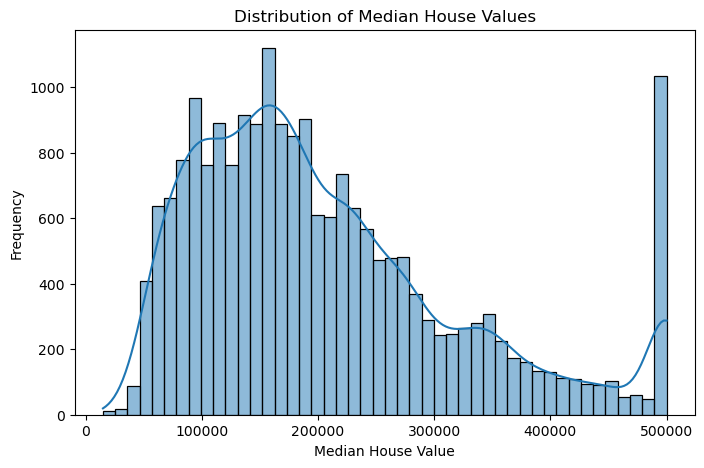

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'], kde=True)
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

In [18]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [19]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical Features: ['ocean_proximity']


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 9)
Testing data: (4128, 9)


In [21]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

# Fit on training data and transform both datasets
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_scaled.shape)
print("Testing data after preprocessing:", X_test_scaled.shape)

Training data after preprocessing: (16512, 13)
Testing data after preprocessing: (4128, 13)


In [22]:
knn_model = KNeighborsRegressor(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

knn_model.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
y_pred = knn_model.predict(X_test_scaled)

print("Predicted values:")
print(y_pred[:10])

Predicted values:
[ 50680.   58840.  317640.2 269260.  299560.  181600.  229680.  242280.
 246760.  483260.6]


In [24]:
comparison = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred
})

comparison.head(10)

,Actual Values,Predicted Values
0,47700.0,50680.0
1,45800.0,58840.0
2,500001.0,317640.2
3,218600.0,269260.0
4,278000.0,299560.0
5,158700.0,181600.0
6,198200.0,229680.0
7,157500.0,242280.0
8,340000.0,246760.0
9,446600.0,483260.6


In [25]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 40763.47684108527
Mean Squared Error: 3758885714.474128
Root Mean Squared Error: 61309.752197135225
R2 Score: 0.7131517124127098


In [26]:
distance_metrics = {
    'Minkowski': {'metric': 'minkowski', 'p': 2},
    'Manhattan': {'metric': 'manhattan'},
    'Chebyshev': {'metric': 'chebyshev'}
}

results = []

for name, params in distance_metrics.items():

    model = KNeighborsRegressor(
        n_neighbors=5,
        **params
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Distance Metric': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df

,Distance Metric,MAE,MSE,RMSE,R2 Score
0,Minkowski,40763.476841,3.758886e+09,61309.752197,0.713152
1,Manhattan,39441.669138,3.521340e+09,59340.882793,0.731279
2,Chebyshev,42807.800581,4.084187e+09,63907.643809,0.688327


In [27]:
print("Best Distance Metric based on MAE:")
print(results_df.loc[results_df['MAE'].idxmin(), 'Distance Metric'])

print("\nBest Distance Metric based on MSE:")
print(results_df.loc[results_df['MSE'].idxmin(), 'Distance Metric'])

print("\nBest Distance Metric based on RMSE:")
print(results_df.loc[results_df['RMSE'].idxmin(), 'Distance Metric'])

print("\nBest Distance Metric based on R2 Score:")
print(results_df.loc[results_df['R2 Score'].idxmax(), 'Distance Metric'])

Best Distance Metric based on MAE:
Manhattan

Best Distance Metric based on MSE:
Manhattan

Best Distance Metric based on RMSE:
Manhattan

Best Distance Metric based on R2 Score:
Manhattan


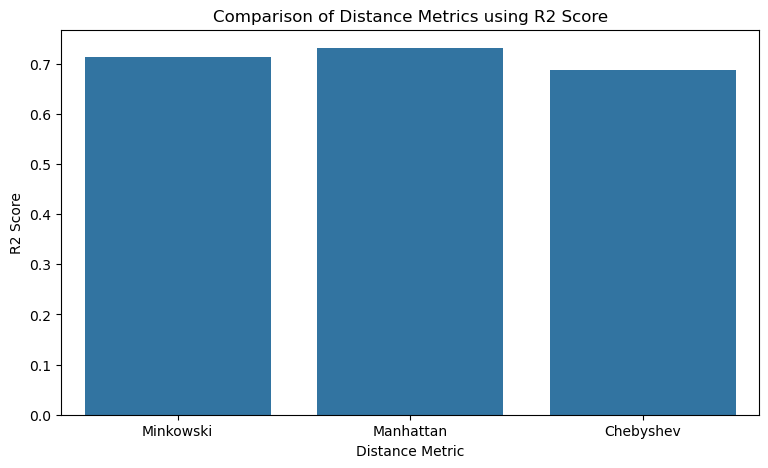

In [28]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Distance Metric',
    y='R2 Score'
)

plt.title('Comparison of Distance Metrics using R2 Score')
plt.xlabel('Distance Metric')
plt.ylabel('R2 Score')

plt.show()

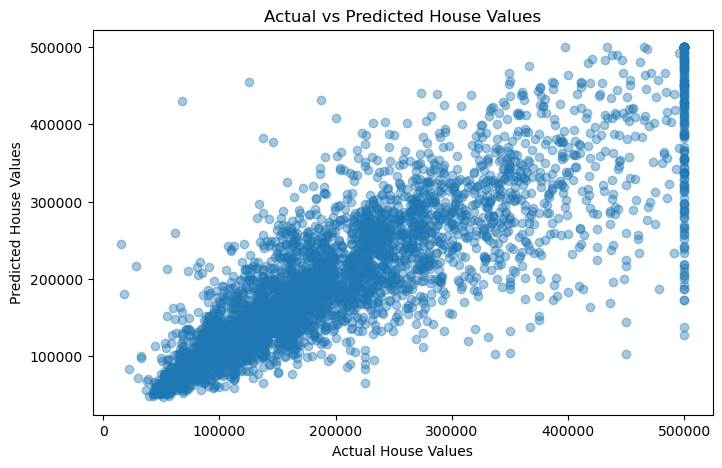

In [29]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')

plt.title('Actual vs Predicted House Values')

plt.show()

In [30]:
new_house = pd.DataFrame({
    'longitude': [-122.23],
    'latitude': [37.88],
    'housing_median_age': [25.0],
    'total_rooms': [5000.0],
    'total_bedrooms': [1000.0],
    'population': [1500.0],
    'households': [800.0],
    'median_income': [5.0],
    'ocean_proximity': ['NEAR BAY']
})

new_house_scaled = preprocessor.transform(new_house)

predicted_house_value = knn_model.predict(new_house_scaled)

print("Predicted House Value:", predicted_house_value[0])

print("Predicted House Value in Dollars:",
      predicted_house_value[0])

Predicted House Value: 296000.0
Predicted House Value in Dollars: 296000.0


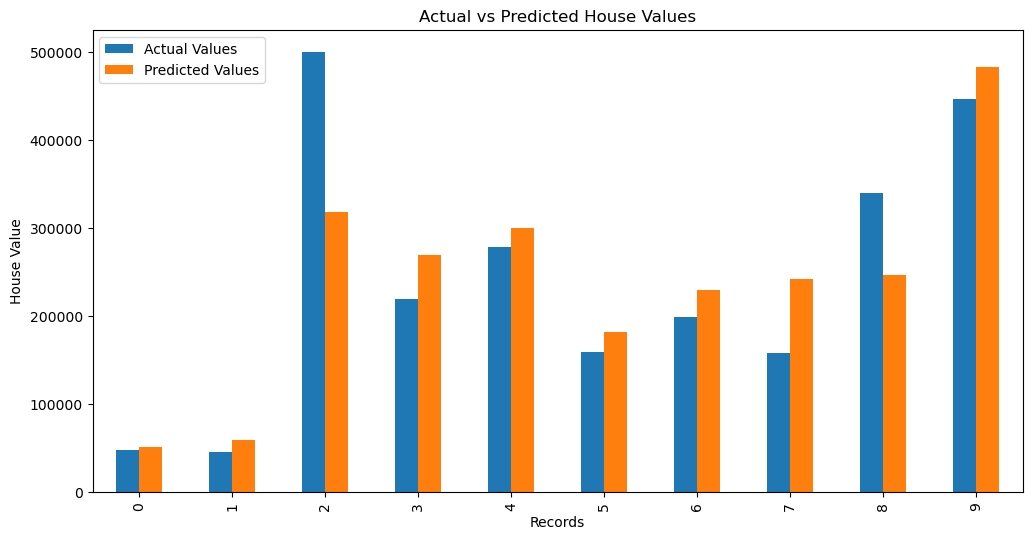

In [31]:
comparison.head(10).plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Actual vs Predicted House Values')
plt.xlabel('Records')
plt.ylabel('House Value')

plt.show()

## Conclusion

In this project, I implemented the K-Nearest Neighbors Regression algorithm using the California Housing Prices dataset.

I started by loading and exploring the dataset using Pandas. I checked the data types, missing values, duplicate records and statistical information.

I handled missing values, converted categorical data into numerical format and standardized the features using StandardScaler.

I divided the dataset into training and testing sets and trained the KNN Regression model using five nearest neighbors.

I evaluated the model using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R2 Score.

I also compared Minkowski, Manhattan and Chebyshev distance metrics to understand how different distance calculations affect model performance.

Finally, I tested a new unseen house record and predicted its median house value.

This task helped me understand regression, data preprocessing, feature scaling, KNN model training and model evaluation.